# Défi NLP medRxiv, projet 1, prédiction de la discipline
## Script 2, modèles de langage neuronaux (deep learning)

**Contexte.** medRxiv est une plateforme de prépublication (*preprints*) en sciences de la santé. Les chercheurs y déposent leurs articles avant leur publication dans une revue, et choisissent eux-mêmes la discipline de leur travail au moment du dépôt. Prédire automatiquement cette discipline à partir de l'abstract permettrait de suggérer une catégorie aux auteurs, de vérifier les choix faits et de mieux classer les preprints. Le script 1 a traité ce problème avec des méthodes classiques (TF-IDF et modèles de machine learning), ce script utilise un modèle de langage neuronal.

**Objectif.** Prédire la discipline d'un preprint (`category_grp`, 16 modalités) à partir de son abstract avec un encodeur pré-entraîné de type BERT, puis comparer au script 1 (TF-IDF et modèles classiques, F1 macro de 0,577 en validation croisée).

**Modèle.** PubMedBERT (`microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract`), une variante biomédicale de BERT pré-entraînée sur les abstracts de PubMed. C'est exactement le type de texte à classer.


   Plan :
 1. données et nettoyage
 2. découpage entraînement, validation, test interne
 3. PubMedBERT et longueur des textes
 4. approche 1 : plongements gelés + régression logistique
 5. approche 2 : ajustement fin avec perte pondérée
 6. comparaison avec le script 1, combinaison et analyse des erreurs
 7. prédiction du fichier de test
 8. conclusion


In [1]:
import re
import html
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from transformers import DataCollatorWithPadding, get_linear_schedule_with_warmup
from transformers.utils import logging as journal_hf
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score

fichier_entrainement = "ClassificationsMedicales_AbstractsTrainingSet.csv.gz"   #abstracts étiquetés
fichier_test = "ClassificationsMedicales_AbstractsTestSet.csv.gz"               #abstracts à classer
fichier_sortie = "predictions_projet1_script2.csv"                              #fichier rendu (ID, pred)
cible = "category_grp"

#réglages de l'ajustement fin (valeurs classiques pour BERT)
NOM_MODELE = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract"   #PubMedBERT
LONGUEUR_MAX = 256          #tokens lus par abstract (BERT accepte jusqu'à 512, 256 va deux fois plus vite)
DEBUT = 64                  #tokens gardés au début d'un abstract trop long (le reste est pris à la fin)
TAILLE_LOT = 16             #abstracts par lot
EPOQUES = 3                 #passages complets sur l'entraînement
TAUX_APPRENTISSAGE = 2e-5   #petit pas, on ajuste un modèle déjà pré-entraîné

appareil = "cuda" if torch.cuda.is_available() else "cpu"
gpu = appareil == "cuda"    #calcul en demi-précision (plus rapide) seulement sur GPU
torch.manual_seed(42)
journal_hf.set_verbosity_error()      #masque les messages techniques de chargement des modèles
journal_hf.disable_progress_bar()
print("Calcul sur", appareil)

Calcul sur cuda


## 1. données et nettoyage
On applique le même nettoyage qu'au script 1 (balises du scraping, doublons, manuscrits retirés). Une différence importante, pas de lemmatisation ni de suppression des mots vides. BERT lit des phrases entières et se sert du contexte et de l'ordre des mots (« not associated » n'a pas le sens de « associated »), on lui donne donc le texte tel quel. Sa propre tokenisation s'occupe des minuscules et découpe les mots rares en sous-mots.

In [2]:
def nettoyer_texte(texte):
    #nettoie un abstract brut, un abstract absent (NaN) devient une chaîne vide (même fonction qu'au script 1)
    if not isinstance(texte, str):
        return ""
    texte = html.unescape(texte)                                         #entités HTML
    texte = re.sub(r"[OC]_SCPLOW", "", texte)                            #petites capitales (le mot est recollé)
    texte = re.sub(r"[OCM]_(?:LINKSMALLFIG|TABLECAPTION|FLOATNO|ST_ABS|TEXTBOX|FIG|TBL|LI)", " ", texte)  #mise en page
    texte = re.sub(r"\S*DTLVardef\S*|\S*HPS_FORMAT\S*|WIDTH=\d+|HEIGHT=\d+|SRC=\S+|ALT=\"[^\"]*\">?", " ", texte)  #figures
    texte = re.sub(r"View larger version \(\d+K\):?|https?://\S+|www\.\S+", " ", texte)   #liens
    texte = re.sub(r"\{[a-zA-Z]+\}", " ", texte)                         #symboles {beta}, {rho}...
    texte = re.sub(r"([a-z])([A-Z][a-z])", r"\1 \2", texte)              #titres collés au texte
    return re.sub(r"\s+", " ", texte).strip()


df = pd.read_csv(fichier_entrainement, sep=";")
df = df.sort_values("date").drop_duplicates("doi", keep="last").drop_duplicates("abstract", keep="last")
df = df[~df["abstract"].str.match(r"\s*Withdrawal statement", case=False)].reset_index(drop=True)
df["texte"] = df["abstract"].map(nettoyer_texte)

disciplines = sorted(df[cible].unique())                   #les 16 disciplines, par ordre alphabétique
indice = {d: i for i, d in enumerate(disciplines)}          #discipline transformée en numéro de 0 à 15
print(len(df), "abstracts,", len(disciplines), "disciplines")

9298 abstracts, 16 disciplines


## 2. découpage entraînement, validation, test interne
toute la validation se fait sur le jeu d'entraînement. Ajuster BERT prend plusieurs minutes par passage et une validation croisée à 5 plis serait trop longue, on utilise donc un **jeu de validation tenu à l'écart**.

| Jeu | Rôle | Part |
|---|---|---|
| entraînement | le modèle ajuste ses poids | 64 % |
| validation | choix de l'époque, du réglage C et du poids de la combinaison | 16 % |
| test interne | mesure finale et comparaison avec le script 1 | 20 % |

Les découpages sont stratifiés (mêmes proportions de disciplines), avec `random_state=42` pour la reproductibilité.

In [3]:
X_app, X_test, y_app, y_test = train_test_split(df["texte"], df[cible], test_size=0.2, stratify=df[cible], random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_app, y_app, test_size=0.2, stratify=y_app, random_state=42)
print(f"entraînement : {len(X_train)} | validation : {len(X_val)} | test interne : {len(X_test)}")

entraînement : 5950 | validation : 1488 | test interne : 1860


## 3. PubMedBERT et longueur des textes
Le tokeniseur de PubMedBERT découpe le texte en **tokens** (mots ou morceaux de mots de son vocabulaire de 30 000 entrées) et ajoute deux tokens spéciaux, `[CLS]` au début et `[SEP]` à la fin. Les modèles BERT ne lisent pas plus de 512 tokens. Pour diviser environ par deux la durée de calcul, on se limite à **256 tokens** par abstract et on mesure combien d'abstracts dépassent cette longueur.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(NOM_MODELE)

#exemple de découpage en tokens
print(tokenizer.tokenize("Myocardial infarction in patients with type 2 diabetes"))

#longueur des abstracts d'entraînement en tokens (tokens spéciaux compris)
n_tokens = np.array([len(ids) for ids in tokenizer(list(X_train))["input_ids"]])
print(f"\nTokens par abstract : médiane {np.median(n_tokens):.0f} | 90 % des abstracts en dessous de {np.percentile(n_tokens, 90):.0f}")
print(f"Abstracts de plus de {LONGUEUR_MAX} tokens : {100 * (n_tokens > LONGUEUR_MAX).mean():.1f} %")

['myocardial', 'infarction', 'in', 'patients', 'with', 'type', '2', 'diabetes']

Tokens par abstract : médiane 390 | 90 % des abstracts en dessous de 619
Abstracts de plus de 256 tokens : 87.1 %


**Stratégie de troncature, le début et la fin :** pour un abstract trop long, on garde ses 64 premiers tokens (contexte et objectif) et ses 190 derniers (résultats et conclusion), et on coupe le milieu, souvent fait de détails de méthode. Garder le début et la fin donne en général de meilleurs résultats que de couper seulement la fin (Sun et al., 2019, *How to fine-tune BERT for text classification*). Les tokens perdus au milieu coûtent un peu d'information, en échange d'un calcul deux fois plus rapide qu'à 512.

**Mise en lots:** chaque lot de 16 abstracts est complété (*padding*) jusqu'à la longueur de son plus long abstract, ce qui est plus rapide que de tout compléter à 256. Le masque d'attention indique au modèle quels tokens sont du remplissage.

In [5]:
def tokeniser(textes):
    #numéros de tokens de chaque abstract, coupés à LONGUEUR_MAX en gardant le début et la fin
    place = LONGUEUR_MAX - 2                                    #2 places pour les tokens spéciaux [CLS] et [SEP]
    resultat = []
    for ids in tokenizer(list(textes), add_special_tokens=False)["input_ids"]:
        if len(ids) > place:                                    #trop long, on coupe le milieu
            ids = ids[:DEBUT] + ids[len(ids) - (place - DEBUT):]
        resultat.append([tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id])
    return resultat


class Abstracts(Dataset):
    #abstracts tokenisés et, si on les connaît, leurs disciplines (numéros 0 à 15)
    def __init__(self, textes, etiquettes=None):
        self.ids = tokeniser(textes)
        self.etiquettes = None if etiquettes is None else [indice[d] for d in etiquettes]

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        exemple = {"input_ids": self.ids[i]}
        if self.etiquettes is not None:
            exemple["labels"] = self.etiquettes[i]
        return exemple


completer = DataCollatorWithPadding(tokenizer)   #complète chaque lot et crée le masque d'attention


def lots(donnees, melanger=False):
    #découpe un jeu de données en lots de TAILLE_LOT abstracts
    return DataLoader(donnees, batch_size=TAILLE_LOT, shuffle=melanger, collate_fn=completer)

## 4. approche 1 : plongements gelés + régression logistique
On utilise PubMedBERT tel quel, sans le modifier (« gelé »). Chaque abstract devient la moyenne des vecteurs de sortie de ses tokens (768 nombres, le remplissage étant exclu grâce au masque), puis une régression logistique pondérée classe ces vecteurs comme au script 1. Son hyperparamètre de régularisation C est choisi sur la validation, puis le modèle est réappris sur entraînement + validation et mesuré sur le test interne.

C'est rapide (un seul passage des textes dans l'encodeur) et cela montre ce que PubMedBERT sait déjà sans ajustement.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

encodeur = AutoModel.from_pretrained(NOM_MODELE).to(appareil).eval()


def plongements(textes):
    #un vecteur par abstract, moyenne des sorties de l'encodeur sur les vrais tokens (hors remplissage)
    vecteurs = []
    with torch.no_grad(), torch.autocast(device_type=appareil, enabled=gpu):
        for lot in lots(Abstracts(textes)):
            lot = {cle: valeur.to(appareil) for cle, valeur in lot.items()}
            sorties = encodeur(**lot).last_hidden_state                 #(lot, tokens, 768)
            masque = lot["attention_mask"].unsqueeze(-1)                 #1 = vrai token, 0 = remplissage
            vecteurs.append(((sorties * masque).sum(1) / masque.sum(1)).float().cpu().numpy())
    return np.vstack(vecteurs)


t0 = time.time()
E_train, E_val, E_test = plongements(X_train), plongements(X_val), plongements(X_test)
print(f"Plongements calculés en {time.time() - t0:.0f} s, taille {E_train.shape[1]}")

#hyperparamètre de régularisation C choisi sur la validation
reglog = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=3000))
f1_C = {C: f1_score(y_val, reglog(C).fit(E_train, y_train).predict(E_val), average="macro") for C in [0.01, 0.1, 1]}
meilleur_C = max(f1_C, key=f1_C.get)
print("F1 macro en validation selon C :", {C: round(f, 3) for C, f in f1_C.items()}, "| C retenu :", meilleur_C)

#réapprentissage sur entraînement + validation, mesure sur le test interne
pred_plongements = reglog(meilleur_C).fit(np.vstack([E_train, E_val]), pd.concat([y_train, y_val])).predict(E_test)
print(f"Test interne : F1 macro = {f1_score(y_test, pred_plongements, average='macro'):.3f}")

del encodeur                  #libère la mémoire du GPU avant l'ajustement fin
if gpu:
    torch.cuda.empty_cache()

Plongements calculés en 46 s, taille 768
F1 macro en validation selon C : {0.01: 0.538, 0.1: 0.497, 1: 0.47} | C retenu : 0.01
Test interne : F1 macro = 0.548


## 5. approche 2: ajustement fin avec perte pondérée
On ajoute au-dessus de PubMedBERT une tête de classification, une couche linéaire qui transforme le vecteur du token `[CLS]` en 16 scores, un par discipline. Pendant l'entraînement, tous les poids du modèle sont ajustés à notre tâche, ceux de l'encodeur comme ceux de la tête.

* **Perte pondérée :** chaque discipline reçoit un poids inversement proportionnel à son effectif. Une erreur sur une petite discipline coûte donc plus cher, ce qui aide le F1 macro, où toutes les disciplines comptent autant.
* **Pas d'apprentissage:** on utilise l'optimiseur AdamW avec un pas de 2e-5. Le pas augmente progressivement au début de l'entraînement, puis diminue jusqu'à la fin. Ce sont des réglages classiques pour ajuster BERT.
* **Entraînement:** à chaque lot d'abstracts, le modèle prédit les disciplines, on mesure son erreur, puis on corrige ses poids. Les calculs sont faits en demi-précision pour aller plus vite sur GPU.
* **Choix de l'époque :** Après chaque passage complet sur les données (une époque), on mesure le F1 macro sur la validation et on garde la meilleure époque, ce qui évite le surapprentissage.

On entraîne sur 3 époques.

In [7]:
from sklearn.utils.class_weight import compute_class_weight

#perte pondérée, poids inversement proportionnel à l'effectif de chaque discipline
poids = compute_class_weight("balanced", classes=np.array(disciplines), y=y_train)
fonction_perte = nn.CrossEntropyLoss(weight=torch.tensor(poids, dtype=torch.float).to(appareil))


def scores_bert(modele, textes):
    #scores du modèle pour les 16 disciplines (une ligne par texte, une colonne par discipline)
    modele.eval()
    scores = []
    with torch.no_grad(), torch.autocast(device_type=appareil, enabled=gpu):
        for lot in lots(Abstracts(textes)):
            lot = {cle: valeur.to(appareil) for cle, valeur in lot.items()}
            scores.append(modele(**lot).logits.float().cpu().numpy())
    return np.vstack(scores)


def entrainer(textes, etiquettes, epoques, textes_val=None, etiquettes_val=None):
    #ajustement fin de PubMedBERT, en gardant la meilleure époque en validation si une validation est fournie
    torch.manual_seed(42)
    modele = AutoModelForSequenceClassification.from_pretrained(NOM_MODELE, num_labels=len(disciplines)).to(appareil)
    chargeur = lots(Abstracts(textes, etiquettes), melanger=True)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=TAUX_APPRENTISSAGE, weight_decay=0.01)
    n_etapes = epoques * len(chargeur)
    planning = get_linear_schedule_with_warmup(optimiseur, int(0.1 * n_etapes), n_etapes)
    echelle = torch.amp.GradScaler(enabled=gpu)        #évite les gradients trop petits en demi-précision
    historique, meilleur = [], {"F1": -1, "poids": None, "époque": epoques}

    for epoque in range(1, epoques + 1):
        modele.train()
        t0, perte_totale = time.time(), 0.0
        for lot in chargeur:
            lot = {cle: valeur.to(appareil) for cle, valeur in lot.items()}
            vraies = lot.pop("labels")
            optimiseur.zero_grad()                                              #1. remettre les gradients à zéro
            with torch.autocast(device_type=appareil, enabled=gpu):
                perte = fonction_perte(modele(**lot).logits.float(), vraies)   #2. prédire et mesurer l'erreur
            echelle.scale(perte).backward()                                     #3. calculer les gradients
            echelle.step(optimiseur)                                            #4. mettre à jour les poids
            echelle.update()
            planning.step()                                                     #ajuste le pas d'apprentissage
            perte_totale += perte.item()

        ligne = {"époque": epoque, "perte (entraînement)": perte_totale / len(chargeur)}
        if textes_val is not None:
            predites = scores_bert(modele, textes_val).argmax(axis=1)
            ligne["F1 macro (validation)"] = f1_score([indice[d] for d in etiquettes_val], predites, average="macro")
            if ligne["F1 macro (validation)"] > meilleur["F1"]:                #meilleure époque, on garde une copie des poids
                meilleur = {"F1": ligne["F1 macro (validation)"], "époque": epoque,
                            "poids": {cle: valeur.detach().cpu().clone() for cle, valeur in modele.state_dict().items()}}
        historique.append(ligne)
        print(", ".join(f"{cle} {valeur:.3f}" if isinstance(valeur, float) else f"{cle} {valeur}" for cle, valeur in ligne.items()),
              f"({time.time() - t0:.0f} s)", flush=True)

    if meilleur["poids"] is not None:
        modele.load_state_dict(meilleur["poids"])
    return modele, pd.DataFrame(historique).set_index("époque"), meilleur["époque"]


modele, historique, meilleure_epoque = entrainer(X_train, y_train, EPOQUES, X_val, y_val)
print("Meilleure époque en validation :", meilleure_epoque)

époque 1, perte (entraînement) 2.031, F1 macro (validation) 0.556 (90 s)
époque 2, perte (entraînement) 1.143, F1 macro (validation) 0.581 (100 s)
époque 3, perte (entraînement) 0.841, F1 macro (validation) 0.600 (99 s)
Meilleure époque en validation : 3


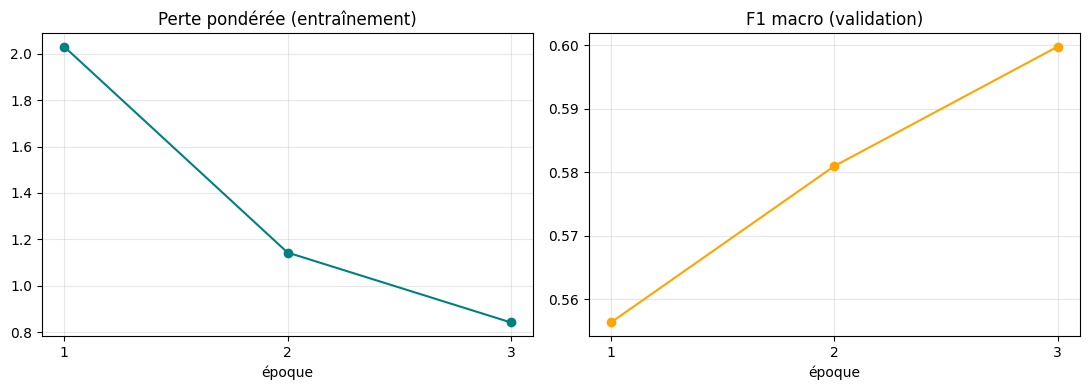

In [8]:
#courbes d'apprentissage, perte d'entraînement et F1 macro de validation à chaque époque
fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(11, 4))
historique["perte (entraînement)"].plot(ax=ax_g, marker="o", color="teal", title="Perte pondérée (entraînement)")
historique["F1 macro (validation)"].plot(ax=ax_d, marker="o", color="orange", title="F1 macro (validation)")
for ax in (ax_g, ax_d):
    ax.set_xticks(historique.index)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. comparaison avec le script 1, combinaison et analyse des erreurs
Toutes les approches sont mesurées sur le même test interne, jamais utilisé jusqu'ici.
* **Script 1 :** TF-IDF des mots et paires de mots + SVM linéaire pondéré (C = 1), à égalité avec le meilleur modèle du script 1 (0,575 contre 0,577 en validation croisée), appris sur entraînement + validation. On utilise la version sans lemmatisation, qui donnait le même score au script 1 et évite de relancer spaCy.
* **Approche 1 :** plongements gelés de PubMedBERT + régression logistique.
* **Approche 2 :** PubMedBERT ajusté.
* **Combinaison (moyenne pondérée):** PubMedBERT s'appuie sur le sens et le SVM sur les mots exacts, ils ne font donc pas toujours les mêmes erreurs. On additionne leurs scores après les avoir mis à la même échelle (division par leur écart-type), avec un poids w pour PubMedBERT et 1 - w pour le SVM. Un seul nombre est réglé sur la validation, le risque de surapprentissage est donc faible, et si le SVM n'apporte rien le poids retenu vaut 1, c'est-à-dire PubMedBERT seul. Le SVM est appris sur l'entraînement seul, pour que la validation soit inédite pour les deux modèles.

Le modèle final est la combinaison avec le poids retenu. Tous les choix sont faits sur la validation, le test interne sert seulement à mesurer.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

tfidf_svm = lambda: make_pipeline(TfidfVectorizer(min_df=2, max_df=0.5, ngram_range=(1, 2), stop_words="english", sublinear_tf=True),
                                  LinearSVC(C=1, class_weight="balanced", random_state=42))

#script 1, TF-IDF + SVM appris sur entraînement + validation
pred_script1 = tfidf_svm().fit(X_app, y_app).predict(X_test)

#approche 2, PubMedBERT ajusté (meilleure époque)
S_val, S_test = scores_bert(modele, X_val), scores_bert(modele, X_test)
pred_ajuste = np.array(disciplines)[S_test.argmax(axis=1)]

#combinaison, SVM appris sur l'entraînement seul
svm_train = tfidf_svm().fit(X_train, y_train)
D_val = svm_train.decision_function(X_val)
echelle_bert, echelle_svm = S_val.std(), D_val.std()   #écart-type des scores de chaque modèle sur la validation


def combiner(S_bert, D_svm, w):
    #moyenne pondérée des scores mis à la même échelle, w pour PubMedBERT et 1 - w pour le SVM
    return w * S_bert / echelle_bert + (1 - w) * D_svm / echelle_svm


#poids de PubMedBERT choisi sur la validation (de 0, SVM seul, à 1, PubMedBERT seul)
f1_w = {w: f1_score(y_val, np.array(disciplines)[combiner(S_val, D_val, w).argmax(axis=1)], average="macro")
        for w in [i / 10 for i in range(11)]}
POIDS = max(f1_w, key=f1_w.get)
print("F1 macro en validation selon le poids de PubMedBERT :", {w: round(f, 3) for w, f in f1_w.items()})
print("Poids retenu :", POIDS)
pred_combinaison = np.array(disciplines)[combiner(S_test, svm_train.decision_function(X_test), POIDS).argmax(axis=1)]

AJUSTE, COMBINAISON = "Approche 2 (PubMedBERT ajusté)", "Combinaison (PubMedBERT + SVM)"
comparaison = pd.DataFrame(
    {nom: {"F1 macro": f1_score(y_test, pred, average="macro"), "exactitude": accuracy_score(y_test, pred)}
     for nom, pred in [("Script 1 (TF-IDF + SVM)", pred_script1),
                       ("Approche 1 (PubMedBERT gelé)", pred_plongements),
                       (AJUSTE, pred_ajuste), (COMBINAISON, pred_combinaison)]}).T

#modèle final, la combinaison avec le poids retenu (PubMedBERT seul si le poids vaut 1)
nom_final = AJUSTE if POIDS == 1 else COMBINAISON
pred_final = pred_combinaison
print("Modèle final :", nom_final)
comparaison.round(3)

F1 macro en validation selon le poids de PubMedBERT : {0.0: 0.568, 0.1: 0.587, 0.2: 0.6, 0.3: 0.61, 0.4: 0.608, 0.5: 0.613, 0.6: 0.605, 0.7: 0.609, 0.8: 0.6, 0.9: 0.604, 1.0: 0.6}
Poids retenu : 0.5
Modèle final : Combinaison (PubMedBERT + SVM)


,F1 macro,exactitude
Script 1 (TF-IDF + SVM),0.569,0.586
Approche 1 (PubMedBERT gelé),0.548,0.562
Approche 2 (PubMedBERT ajusté),0.613,0.624
Combinaison (PubMedBERT + SVM),0.612,0.623


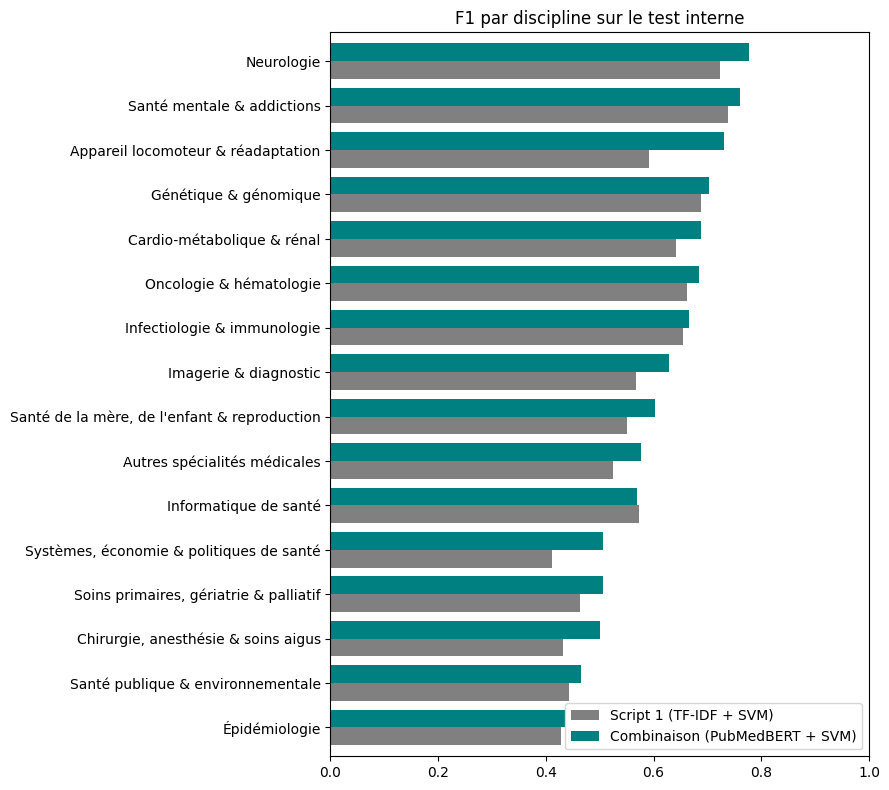

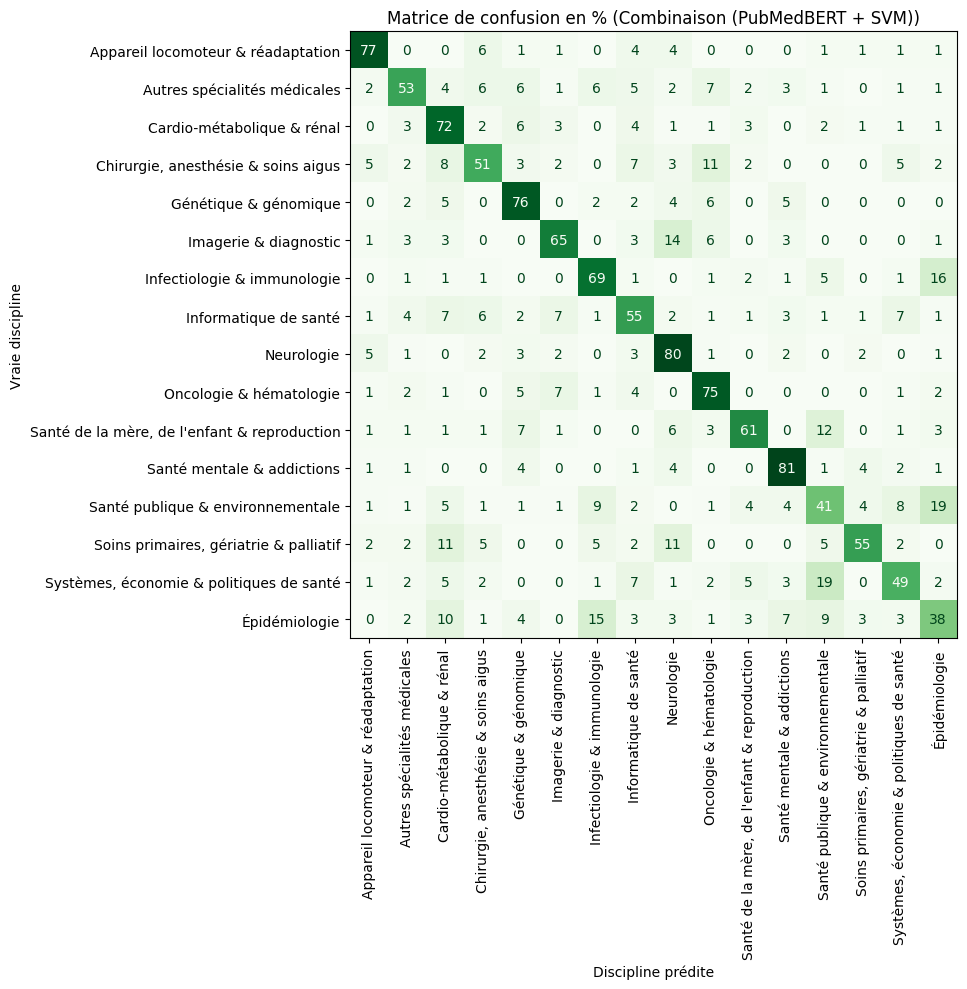

Confusions les plus fréquentes (vraie, prédite, nombre) :
Santé publique & environnementale         Épidémiologie                        32
Épidémiologie                             Infectiologie & immunologie          28
Infectiologie & immunologie               Épidémiologie                        23
Épidémiologie                             Cardio-métabolique & rénal           20
Systèmes, économie & politiques de santé  Santé publique & environnementale    18
Épidémiologie                             Santé publique & environnementale    17


In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#F1 par discipline, script 1 et modèle final
f1_disc = pd.DataFrame({"Script 1 (TF-IDF + SVM)": f1_score(y_test, pred_script1, average=None, labels=disciplines),
                        nom_final: f1_score(y_test, pred_final, average=None, labels=disciplines)},
                       index=disciplines).sort_values(nom_final)
ax = f1_disc.plot(kind="barh", figsize=(9, 8), width=0.8, xlim=(0, 1), color=["grey", "teal"],
                  title="F1 par discipline sur le test interne")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#matrice de confusion du modèle final, en % de chaque ligne
confusion = confusion_matrix(y_test, pred_final, labels=disciplines)
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(100 * confusion / confusion.sum(axis=1, keepdims=True), display_labels=disciplines).plot(
    ax=ax, cmap="Greens", colorbar=False, values_format=".0f", xticks_rotation=90)
ax.set(xlabel="Discipline prédite", ylabel="Vraie discipline", title=f"Matrice de confusion en % ({nom_final})")
plt.tight_layout()
plt.show()

#confusions les plus fréquentes
paires = pd.DataFrame(confusion, index=disciplines, columns=disciplines).stack()
paires = paires[[vraie != predite for vraie, predite in paires.index]]
print("Confusions les plus fréquentes (vraie, prédite, nombre) :\n" + paires.nlargest(6).to_string())

## 7. prédiction du fichier de test
* PubMedBERT et le SVM sont **réappris sur les 9 298 abstracts** avant la prédiction, avec les réglages choisis en partie 6 (nombre d'époques, poids de la combinaison).
* Le fichier de test passe par le même nettoyage. Les abstracts vides ou presque (moins de 3 mots) reçoivent la discipline la plus fréquente, comme au script 1.
* Le code vérifie le fichier de test (colonne `abstract`, ID uniques) puis le fichier rendu (colonnes `ID` et `pred`, une ligne par abstract, libellés exacts) avant de l'écrire.

* PubMedBERT et le SVM sont **réappris sur les 9 298 abstracts** avant la prédiction, avec les réglages choisis en partie 6 (nombre d'époques, poids de la combinaison).

In [11]:
REAPPRENDRE_SUR_TOUT = True

if REAPPRENDRE_SUR_TOUT:
    del modele                                                    #libère la mémoire du GPU
    if gpu:
        torch.cuda.empty_cache()
    modele = entrainer(df["texte"], df[cible], meilleure_epoque)[0]
    svm_train = tfidf_svm().fit(df["texte"], df[cible])           #le poids de la partie 6 est gardé

#vérification et nettoyage du fichier de test
df_test = pd.read_csv(fichier_test, sep=";")
assert "abstract" in df_test.columns, "le fichier de test doit avoir une colonne abstract"
assert "ID" not in df_test.columns or df_test["ID"].is_unique, "les ID du fichier de test doivent être uniques"
textes_test = df_test["abstract"].map(nettoyer_texte)

#prédiction avec le modèle final, discipline la plus fréquente pour les abstracts vides ou presque
S = scores_bert(modele, textes_test)
pred = np.array(disciplines)[combiner(S, svm_train.decision_function(textes_test), POIDS).argmax(axis=1)]
trop_court = (textes_test.str.split().str.len() < 3).to_numpy()
defaut = df[cible].value_counts().idxmax()
pred = np.where(trop_court, defaut, pred)

#fichier rendu (numérotation à partir de 1 si le fichier n'a pas d'ID), vérifié avant d'être écrit
identifiants = df_test["ID"] if "ID" in df_test.columns else pd.RangeIndex(1, len(df_test) + 1)
sortie = pd.DataFrame({"ID": identifiants, "pred": pred})
assert list(sortie.columns) == ["ID", "pred"] and len(sortie) == len(df_test), "format du fichier rendu incorrect"
assert sortie["pred"].isin(disciplines).all(), "une prédiction n'est pas un libellé du jeu d'entraînement"
sortie.to_csv(fichier_sortie, index=False)
print(f"{len(sortie)} prédictions dans {fichier_sortie} ({nom_final}), dont {trop_court.sum()} abstracts vides ou presque ({defaut}), format vérifié")

/tmp/ipykernel_1138/357511680.py:42: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  planning.step()                                                     #ajuste le pas d'apprentissage


époque 1, perte (entraînement) 1.822 (144 s)
époque 2, perte (entraînement) 1.034 (142 s)
époque 3, perte (entraînement) 0.771 (142 s)
1940 prédictions dans predictions_projet1_script2.csv (Combinaison (PubMedBERT + SVM)), dont 645 abstracts vides ou presque (Épidémiologie), format vérifié


## 8. conclusion

**Démarche**
* Encodeur pré-entraîné biomédical (PubMedBERT) sur le texte nettoyé mais non lemmatisé, avec une troncature à 256 tokens qui garde le début et la fin des abstracts trop longs.
* Deux usages de l'encodeur, des plongements gelés + régression logistique et un ajustement fin avec tête de classification et perte pondérée pour le déséquilibre, puis une combinaison avec le SVM du script 1.
* Validation sur le jeu d'entraînement seul, avec un jeu de validation pour les choix (époque, C, poids de la combinaison) et un test interne de 1 860 abstracts pour la mesure finale et la comparaison avec le script 1 sur les mêmes abstracts.

**Résultats**
* **PubMedBERT ajusté (F1 macro de 0,613, exactitude 0,624) et sa combinaison avec le SVM (0,612, exactitude 0,623) sont à égalité**, nettement devant le script 1 (0,569 sur les mêmes abstracts). Le gain d'environ 0,04 dépasse l'incertitude d'environ 0,02 liée au découpage.
* Les plongements gelés font moins bien que le script 1 (0,548). Sans ajustement, PubMedBERT résume l'abstract sans savoir quelle information compte pour la discipline. L'ajustement fin est donc nécessaire.
* Pour la combinaison, le poids retenu sur la validation est 0,5 (autant PubMedBERT que le SVM), avec un F1 macro de validation de 0,613 contre 0,599 pour PubMedBERT seul. Sur le test interne ce gain disparaît (0,612 contre 0,613), il venait donc surtout du hasard de la validation. Le modèle final est la combinaison, choisie sur la validation comme prévu, mais le SVM n'apporte presque rien de plus que PubMedBERT.
* Le F1 macro de validation monte à chaque époque (0,557, 0,581 puis 0,599), une époque de plus pourrait encore apporter un peu.
* Par rapport au script 1, les plus gros gains du modèle final portent sur l'appareil locomoteur (F1 d'environ 0,59 à 0,73), les systèmes de santé (0,41 à 0,51), la chirurgie (0,43 à 0,50), l'imagerie (0,57 à 0,63) et les autres spécialités (0,52 à 0,58). BERT tient compte du contexte et rapproche les synonymes (« heart attack » et « myocardial infarction »), ce qui aide quand le vocabulaire seul ne suffit pas. La génétique, l'infectiologie et l'informatique de santé, déjà bien reconnues par leurs mots-clés, ne gagnent presque rien.

**Limites**
* Les disciplines transversales restent les moins bien reconnues (épidémiologie autour de 0,44, santé publique 0,47, soins primaires et systèmes de santé 0,51), et les confusions les plus fréquentes sont entre elles (32 abstracts de santé publique et 23 d'infectiologie prédits en épidémiologie, 28 d'épidémiologie prédits en infectiologie). Une partie vient de l'étiquetage déclaratif, aucun modèle ne peut dépasser ce bruit.
* 87 % des abstracts dépassent 256 tokens (médiane de 390) et perdent leur milieu. Passer à 512 (`LONGUEUR_MAX = 512` et `DEBUT = 128`) doublerait la durée pour un gain probablement faible.
* L'ajustement fin demande un GPU et environ 10 minutes, contre quelques minutes sur un processeur pour le script 1. Le modèle est aussi beaucoup moins interprétable (pas de liste de mots caractéristiques).
* Un seul découpage entraînement, validation et test, faute de temps de calcul pour une validation croisée. Les scores ont donc une incertitude de l'ordre de ± 0,02.
* Un tiers des abstracts du fichier de test (645 sur 1 940) sont vides ou presque. Ils reçoivent la discipline la plus fréquente, quel que soit le modèle, ce qui fera baisser le F1 macro sur le test.
